# Projet: Machine Learning pour reconnaissance d'oiseaux

## 1)Import des librairies etc

In [4]:
import numpy as np
import tensorflow as tf
import matplotlib.pyplot as plt

from tensorflow.keras.datasets import mnist
(x_train, y_train), (x_test, y_test) = mnist.load_data()

print("\nShapes :")
print("x_train :", x_train.shape)
print("y_train :", y_train.shape)
print("x_test :", x_test.shape)
print("y_test :", y_test.shape)

X_train = (x_train[:10000].reshape(10000, 784) / np.float32(255.0))
X_test  = (x_test[:2000].reshape(2000, 784)    / np.float32(255.0))

Y_train = tf.keras.utils.to_categorical(y_train[:10000], 10).astype(np.float32)
Y_test  = tf.keras.utils.to_categorical(y_test[:2000],   10).astype(np.float32)


print(X_train.shape)   # (60000, 784)
print(Y_train.shape)   # (60000, 10)


Shapes :
x_train : (60000, 28, 28)
y_train : (60000,)
x_test : (10000, 28, 28)
y_test : (10000,)
(10000, 784)
(10000, 10)


## 2)Téléchargement audio

In [ ]:
#VRAI DONNEE
X_train_v=np.load("images.npy")


## 3)Nettoyage / normalisation

## 4)Transformation en spectrogramme

## 5)Filtrage fréquentiel manuel: Otsu

In [4]:
# de 1kHz à 10kHz


## 6)Extraction de caractéristiques

## 7)Vecteur numérique

In [5]:
Problème du code actuel:
-L'auto-encodeur ne marche pas bien, jsp pourquoi
-Il faut qu'on lie les algo 

SyntaxError: invalid syntax (2415351222.py, line 1)

## 8)Auto-encodeur 

In [19]:
'''
encodeur type: 4096-512-128-32
 L'auto-encodeur se code avec les différentes fonctions:
 
 -init_parameter: rien à changer par rapport au mlp, permet d'initialiser W et B
 
 -linear forward: on l'utilise aussi mais avec la sigmoid à la fin pas la softmax
 
 -backward: même utilisation pour regarder en arrière les poids etc
 
 -update: même utilisation pour update les poids dans les couches précédentes
 
 -Fonction de loss: Remplace cross_entropy. Compare l'image reconstruite à l'originale.
 Retourne la loss et le gradient dZ pour lancer la backprop.
 
 -Mini-Batch: ça va être la pipeline d'entrainement utilisé mais la sortie ça ne sera pas des labels Y mais simplement X
 
 -Encode: Va couper le réseau au milieu (au goulot) à la fin et récuperer l'information sous image réduite.
 Fait tourner le forward uniquement jusqu'au goulot (couche du milieu). Retourne la représentation compressée 
 
 -decode:Fait tourner le forward depuis le goulot jusqu'à la sortie. Utile pour visualiser ce que le réseau reconstruit et vérifier qu'il apprend bien.
 
 -vue_reconstruite: fonction pas absolument nécéssaire mais j'ai galérer à debuger sans elle donc elle sert de fou, 
 Affiche côte à côte n images originales et leurs reconstructions.si les reconstructions sont floues ou fausses, le réseau n'apprend pas.
 '''
def MSE_reconstruction(X, X_reconstruit, Z_L):  #ADAPTE POUR SIGMOID CAR MEILLEUR FONCTION D'ACTIVATION POUR AUTO-ENCODEUR
    N = X.shape[0]          # nombre d'exemples dans le batch
    nb_pixels = X.shape[1]  # 16384 pour du 128x128
    
    loss = (1/(N * nb_pixels)) * np.sum((X - X_reconstruit)**2)
    dA = (2 / (N * nb_pixels)) * (X_reconstruit - X)
    dZ=dA*dsigmoid(Z_L)
    return loss, dZ

def encode(X,W,B, act):
    milieu=len(W)//2
    X_encoded={0:X}
    for i in range(1,milieu+1):
        A_prev=X_encoded[i-1]
        Z = np.dot(A_prev, W[i]) + B[i]
        X_encoded[i]=act(Z)
    return X_encoded[milieu]
    
def decode(X_encoded,W,B,act,act_finale):
    milieu=len(W)//2
    X_decoded={milieu:X_encoded}
    for i in range(milieu+1,len(W)+1):
        A_prev=X_decoded[i-1]
        Z = np.dot(A_prev, W[i]) + B[i]
        if i < len(W):
            X_decoded[i] = act(Z)          # couche normales
        else:
            X_decoded[i] = act_finale(Z)      # couche de sortie
    return X_decoded[len(W)]

def vue_reconstruite(X, W, B, act, act_finale,D, E, n=5):   #FONCTION A VIRER A LA FIN, AIDE A DEBUGUER MAIS DONNER PAR UNE IA
    """
    Affiche n images originales et leurs reconstructions côte à côte.
    X : batch d'images shape (N, 16384)
    n : nombre d'images à afficher
    """
    fig, axes = plt.subplots(2, n, figsize=(n * 3, 6))
    for i in range(n):
        # reconstruction
        x_single = X[i:i+1]                                    # shape (1, 16384)
        x_encoded = encode(x_single, W, B, act)
        x_decoded = decode(x_encoded, W, B, act, act_finale)   # shape (1, 16384)
        # reshape en image 128x128
        original     = x_single.reshape(D, E)
        reconstruit  = x_decoded.reshape(D, E)
        # ligne du haut : originales
        axes[0, i].imshow(original, cmap="gray")
        axes[0, i].axis("off")
        if i == 0:
            axes[0, i].set_title("Original", fontsize=12)
        # ligne du bas : reconstruites
        axes[1, i].imshow(reconstruit, cmap="gray")
        axes[1, i].axis("off")
        if i == 0:
            axes[1, i].set_title("Reconstruit", fontsize=12)
    plt.tight_layout()
    plt.show()


# 128*128 = 16384 pixels en entrée
# goulot en 8*8 = 64
layer_sizes = [16384, 2048, 512, 128, 64,   # encodeur
               128, 512, 2048, 16384]        # décodeur

## Test (entrainement + test) de l'auto-encodeur

Epoch 0/500 — Loss: 0.2318
Epoch 5/500 — Loss: 0.1280
Epoch 10/500 — Loss: 0.0744
Epoch 15/500 — Loss: 0.0708
Epoch 20/500 — Loss: 0.0688
Epoch 25/500 — Loss: 0.0676
Epoch 30/500 — Loss: 0.0667
Epoch 35/500 — Loss: 0.0657
Epoch 40/500 — Loss: 0.0647
Epoch 45/500 — Loss: 0.0637
Epoch 50/500 — Loss: 0.0625
Epoch 55/500 — Loss: 0.0615
Epoch 60/500 — Loss: 0.0603
Epoch 65/500 — Loss: 0.0592
Epoch 70/500 — Loss: 0.0579
Epoch 75/500 — Loss: 0.0566
Epoch 80/500 — Loss: 0.0552
Epoch 85/500 — Loss: 0.0540
Epoch 90/500 — Loss: 0.0529
Epoch 95/500 — Loss: 0.0517
Epoch 100/500 — Loss: 0.0506
Epoch 105/500 — Loss: 0.0496
Epoch 110/500 — Loss: 0.0486
Epoch 115/500 — Loss: 0.0476
Epoch 120/500 — Loss: 0.0467
Epoch 125/500 — Loss: 0.0459
Epoch 130/500 — Loss: 0.0451
Epoch 135/500 — Loss: 0.0443
Epoch 140/500 — Loss: 0.0436
Epoch 145/500 — Loss: 0.0430
Epoch 150/500 — Loss: 0.0423
Epoch 155/500 — Loss: 0.0417
Epoch 160/500 — Loss: 0.0411
Epoch 165/500 — Loss: 0.0405
Epoch 170/500 — Loss: 0.0400
Epoch 1

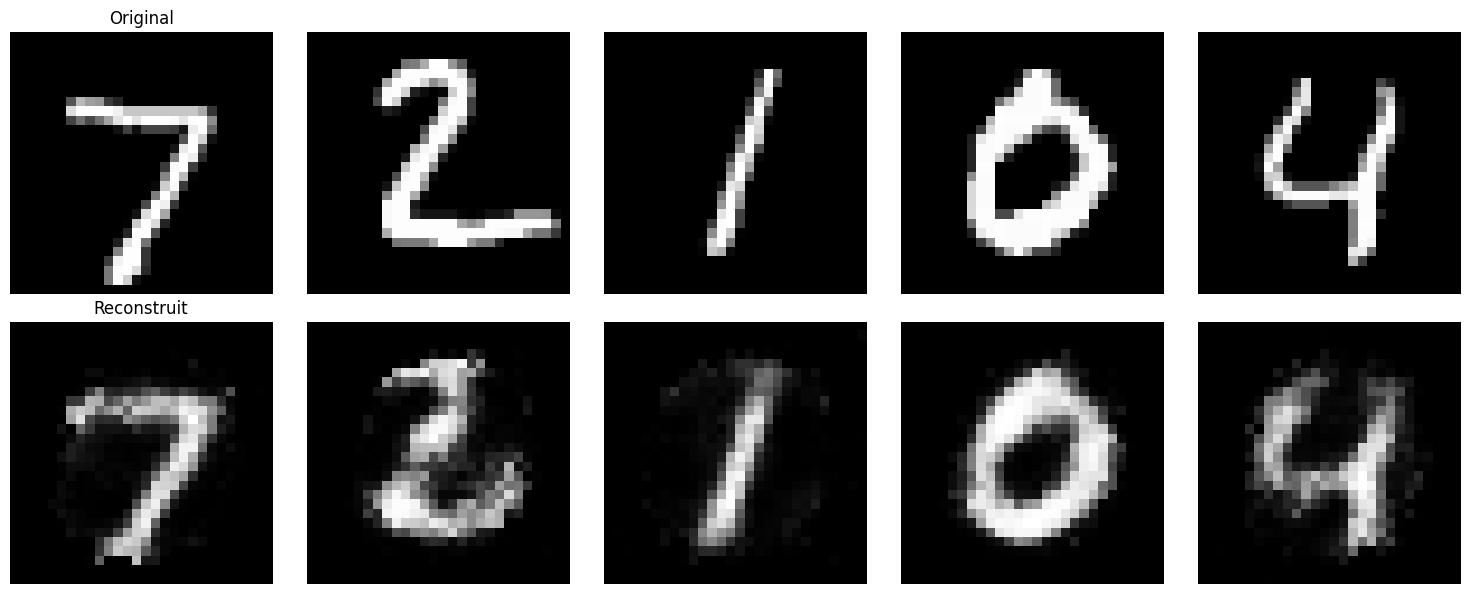

In [6]:
'''
Si test pour sigmoid: mettre 'xavier', act=sigmoid pour le mini_batch et dans vue_reconstruite, mettre act=sigmoid
'''
W, B = init_params(
    layer_sizes=[784, 256, 64, 256, 784],
    init_type="he",
    seed=42
)

act = Relu    # ← sigmoid au lieu de ReLU, plus stable pour l'auto-encodeur
act_f = sigmoid
D=28
E=28

W, B, cout2 = Mini_Batch(
    X=X_train,
    Y=X_train,
    nb_epoch=500,
    Lr=0.1,         # ← remonté car sigmoid a des gradients naturellement petits
    W=W,
    B=B,
    Nom_tech_Loss=MSE_reconstruction,
    Nom_tech_activation=act,
    act_finale=act_f,
    batch_size=128,
    clip=5.0         # ← clip moins agressif
)
vue_reconstruite(X_test, W, B, act=Relu, act_finale=sigmoid,D=D, E=E, n=5)

## 9)MLP (réseau dense simple)

In [2]:
'''
Etapes global:
1. propagation avant: Forward
2. calcul erreur: Loss
3. backpropagation
4. mise à jour poids: update
5. recommencer: pour chaque epoch

VARIABLES:
W: Dict, à chaque clé une couche du réseau, à chaque valeur une liste des poids de chaque neurones de la couche
B: Dict des Biais, donc comme W
Zs: Dict des forward (avant activation), même structure que W
As: Dict des predictions ( f(Z) ), même structure que W, A[0] c'est l'entrée X, A[1] la liste des pred de la première couche etc


Ici pour la fonction d'activation à la fin du forward,
on a le choix entre plusieurs fonctions:
Relu, Sigmoid et d'autres (que j'ai pas codés parcque flemme),
on discute pour choisir laquelle utiliser quand on devra entrainer le modèle
''' 

def Relu(z):
    return np.maximum(0,z)
def dRelu(z):
    return (z > 0).astype(float)


def sigmoid(z):
    return 1/(1+np.exp(-z))
def dsigmoid(z):
    s = sigmoid(z)
    return s * (1 - s)
    
def linear_forward(X, W, B, act,act_finale):
    Zs={}
    As={0: X}
    L=len(W) #nombre de couche de neurones dans le réseau
    for l in range(1, L + 1):
        A_prev = As[l - 1]
        Z = np.dot(A_prev, W[l]) + B[l]
        Zs[l] = Z
        if l < L:
            As[l] = act(Z)          # couche normales
        else:
            As[l] = act_finale(Z)      # couche de sortie
    return Zs, As
'''
Prends la valeur prédite par le modèle A et la transforme en proba 
chaque neuronne de la couche finale represente une classe d'animaux,
et sa proba après softmax est donc sa chance d'être de cette classe,
la prédiction fianle du modèle sera celle de la proba la plus haute
'''
def softmax(Z):    
    Z = Z - np.max(Z, axis=1, keepdims=True)
    expZ = np.exp(Z)
    return expZ / np.sum(expZ, axis=1, keepdims=True)
    
'''
3 types de fonctions de pertes que l'on peut utiliser,
j'ai coder les trois, à nous de faire le choix de laquelle utiliser,
mais la cross-entropy est sûrement mieux
Dans les fait j'ai codé comme il faut que la cross_entropy car elle présentait de meilleurs résulats

'''
def MSE(Y_r,  A_L):   # ELLE AUSSI
    N = Y_p.shape[0]
    J = (1/N) * np.sum((A_L - Y_r)**2)
    dA = (2/N) * (A_L - Y_r)
    return J, dA

def cross_entropy(Y, A_L):
    """
    Loss + gradient dZ directement pour softmax + cross-entropy.
    dZ_L = A_L - Y  (simplification mathématique exacte)
    Y doit être one-hot, shape (N, C). #Ca jsp ce que ça veut dire par contre
    """
    eps = 1e-8
    N = Y.shape[0]
    J = -(1 / N) * np.sum(Y * np.log(A_L + eps))
    dZ_L = (A_L - Y) / N   # divisé par N car on normalise
    return J, dZ_L 
    
def Log_loss(Y_r, A_L):  # CES FONCTIONS SONT CODES MAIS PAS DU TOUT ADAPTE A NOTRE PIPELINE
    eps = 1e-8            #DONC JE LES AI PAS MAJ et ADAPTE
    N = Y_p.shape[0]
    J=-(1/N)*np.sum((Y_r*np.log(A_L+eps))+(1-Y_r)*np.log(1-A_L+eps))
    dA=-(1/N)*((Y_r/(A_L+eps))-((1-Y_r)/(1-A_L+eps)))
    return J,dA

def Loss_choisi(nom_technique, Y_r, Y_p, Z_final=None):
    if nom_technique==cross_entropy:
        J, dZ_L=nom_technique(Y_r,Y_p)
    elif nom_technique==MSE_reconstruction:
        J,dZ_L=nom_technique(Y_r,Y_p, Z_final)
    else:
        print("La fonction de loss choisi n'est pas encore bien codé car pas adapté")
        print("Donc toute la suite peut être considéré faux")
    return J, dZ_L  #On récup la valeur de la loss et DA

'''
Cette fonction ne sert plus à rien vu qu'on va rester avec le combo Softmax+cross-entropy
'''
def activation_backward(nom_act, Z):
    if nom_act == Relu:
        return dRelu(Z)
    elif nom_act == sigmoid:
        return dsigmoid(Z)
    else:
        raise ValueError("Activation non reconnue.")

'''
Y: Les réultats
W: Dico des poids par couche
Zs: Dico des val prédit dans chaque neurone (avant application de non-linearité) par couche
As: Dico des val prédites après softmax par couche
dZ_L: Liste de la variation des val prédites à la dernière couche, calculé dans cross_entropy
gradients_W: Dico des dw par couche
gradients_B: Dico des db par couche
Fonctionnement: on parcourt le réseau à l'envers puisqu'on remonte les erreurs
                à chaque couche n, on choppe le A de la couche n-1,avec, on calcule
                dw de la couche (liste de couche et une valeur par neurone)
'''

def backward(Y, W, Zs, As, dZ_L, nom_act,clip=None):#Fonction complexe, remonte chaque couche depuis la fin, pour trouver les dZ, les dA, les dw et db
    gradients_W = {}
    gradients_B = {}
    L = len(W)
    dZ_current = dZ_L
    for l in reversed(range(1, L + 1)):
        if clip is not None:
            dZ_current = np.clip(dZ_current, -clip, clip)
        A_prev = As[l - 1]
        gradients_W[l] = np.dot(A_prev.T, dZ_current)
        gradients_B[l] = np.sum(dZ_current, axis=0, keepdims=True)
        if l > 1:
            dA_prev = np.dot(dZ_current, W[l].T)
            dZ_current = dA_prev * activation_backward(nom_act, Zs[l - 1])

    return gradients_W, gradients_B
    
def update(dw,db,w,b, Lr):
    L=len(w)
    W_new={}
    B_new={}
    for i in range(1,L+1):
        W_new[i]=w[i]-Lr*dw[i]
        B_new[i]=b[i]-Lr*db[i]
    return W_new,B_new

def init_params(layer_sizes, init_type="he", seed=None):
    """
    Initialise les poids et biais du réseau.

    Parameters
    ----------
    layer_sizes : list
        Liste contenant le nombre de neurones par couche.
        
        Exemple :
        [4, 16, 8, 3]
        
        signifie :
        4 entrées
        -> couche cachée 16 neurones
        -> couche cachée 8 neurones
        -> sortie 3 neurones

    init_type : str
        "he"      -> conseillé pour ReLU
        "xavier"  -> conseillé pour sigmoid/tanh
        "random"  -> petit aléatoire simple

    seed : int ou None
        Pour reproductibilité.

    Returns
    -------
    W : dict
        Dictionnaire des matrices de poids.

    B : dict
        Dictionnaire des biais.
    """

    if seed is not None:
        np.random.seed(seed)
    W = {}
    B = {}
    L = len(layer_sizes) - 1
    for l in range(1, L + 1):
        n_prev = layer_sizes[l - 1]
        n_curr = layer_sizes[l]
        # ==========================================
        # INITIALISATION DES POIDS
        # ==========================================
        if init_type == "he":
            # très bon pour ReLU
            W[l] = np.random.randn(n_prev, n_curr) * np.sqrt(2 / n_prev)
        elif init_type == "xavier":
            # mieux pour sigmoid/tanh
            W[l] = np.random.randn(n_prev, n_curr) * np.sqrt(1 / n_prev)
        elif init_type == "random":
            W[l] = np.random.randn(n_prev, n_curr) * 0.01
        else:
            raise ValueError("Type d'initialisation inconnu")
        # ==========================================
        # BIAIS
        # ==========================================
        B[l] = np.zeros((1, n_curr))
    return W, B
'''
De la même manière que pour la loss, j'ai coder les 3 manières 'classiques' de faire de l'update de nos poids en backpropagation: l'entrainement
Batch: très lent et couteux mais très réaliste, erreur faible
Stocastique: Super rapide car n'update qu'après une prédiction, mais ducoup moins fiable et moins précis
Mini-batch: Un mélange entre les deux, à la fois précis et rapide, on va sûrement l'utiliser mais au moins on a les atres au cas où
Au final j'ai pas fait stochastique flemme ça sert à rien
'''

def Batch_complet(X,nb_epoch, Lr, Y,W,B, Nom_tech_Loss,Nom_tech_activation,act_finale):
    cout=[]
    L=len(W)
    for i in range(nb_epoch):
        Zs, As=linear_forward(X,W,B,Nom_tech_activation,act_finale)
        J,dZ_L=Loss_choisi(Nom_tech_Loss, Y,As[L])
        gradients_w,gradients_b=backward(Y,W,Zs,As,dZ_L,Nom_tech_activation)
        W,B=update(gradients_w,gradients_b,W,B,Lr)
        cout.append(J)
        if i % 5 == 0:
            print(f"Epoch {i}/{nb_epoch} — Loss: {J:.4f}")
    return W,B, cout
                         
def Mini_Batch(X, nb_epoch, Lr, Y, W, B, Nom_tech_Loss, Nom_tech_activation,act_finale, batch_size=64, clip=None):
    cout = []
    L = len(W)
    N = X.shape[0]
    for i in range(nb_epoch):
        indices = np.random.permutation(N)
        X_s = X[indices]
        Y_s = Y[indices]
        epoch_loss = []
        for j in range(0, N, batch_size):
            X_batch = X_s[j:j + batch_size]
            Y_batch = Y_s[j:j + batch_size]
            Zs, As = linear_forward(X_batch, W, B, Nom_tech_activation,act_finale)         
            J, dZ_L = Loss_choisi(Nom_tech_Loss, Y_batch, As[L], Zs[L])
            gradients_w, gradients_b = backward(Y_batch, W, Zs, As, dZ_L, Nom_tech_activation, clip=clip)
            W, B = update(gradients_w, gradients_b, W, B, Lr)
            epoch_loss.append(J)
        mean_loss = np.mean(epoch_loss)
        cout.append(mean_loss)
        if i % 5 == 0:
            print(f"Epoch {i}/{nb_epoch} — Loss: {mean_loss:.4f}")
    return W, B, cout

## Test du modèle avec MNIST

### Entrainement

In [17]:

a=3
if a==2:
    W, B = init_params(layer_sizes=[784, 128, 64, 10], init_type="xavier", seed=42)
elif a==1:
    W, B = init_params(layer_sizes=[784, 32, 16, 10], init_type="he", seed=42)
    for l in W:
        print(f"Couche {l} — W: {W[l].shape}, B: {B[l].shape}")
elif a==3:
    W, B = init_params(layer_sizes=[784, 128, 64, 10], init_type="he", seed=42)

act = Relu  #défini ici, réutilisé partout en dessous
act_f=softmax

W, B, cout = Mini_Batch(
    X=X_train,
    nb_epoch=50,
    Lr=0.01,
    Y=Y_train,
    W=W,
    B=B,
    Nom_tech_Loss=cross_entropy,
    Nom_tech_activation=act,
    act_finale=act_f,
    batch_size=64,
    clip=None
)

Epoch 0/50 — Loss: 1.7656
Epoch 5/50 — Loss: 0.4055
Epoch 10/50 — Loss: 0.3075
Epoch 15/50 — Loss: 0.2596
Epoch 20/50 — Loss: 0.2255
Epoch 25/50 — Loss: 0.2011
Epoch 30/50 — Loss: 0.1790
Epoch 35/50 — Loss: 0.1607
Epoch 40/50 — Loss: 0.1450
Epoch 45/50 — Loss: 0.1312


### Test

Accuracy : 92.05%

Classe      Precision     Recall         F1
------------------------------------------
0               0.956      0.989      0.972
1               0.967      0.991      0.979
2               0.887      0.932      0.909
3               0.896      0.918      0.907
4               0.947      0.908      0.927
5               0.945      0.860      0.901
6               0.902      0.927      0.914
7               0.918      0.873      0.895
8               0.909      0.885      0.897
9               0.881      0.912      0.896
------------------------------------------
Moyenne         0.921      0.920      0.920


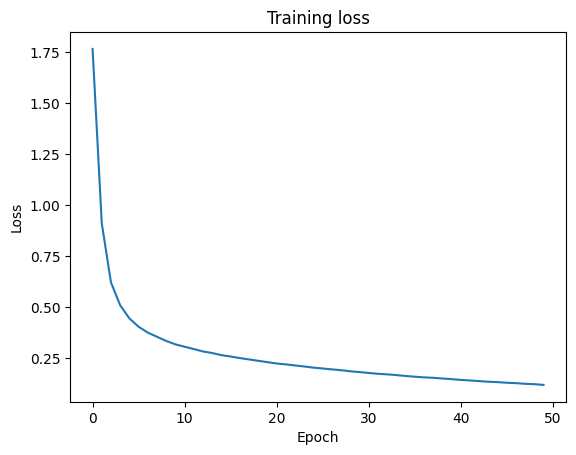

In [19]:
Zs_test, As_test = linear_forward(X_test, W, B, act, act_f)
L = len(W)
pred = np.argmax(As_test[L], axis=1)

y_test_subset = y_test[:len(pred)]  # ← alignement une fois pour toutes

# ── Accuracy ──────────────────────────────────────────────────────────────────
accuracy = np.mean(pred == y_test_subset)
print(f"Accuracy : {accuracy * 100:.2f}%")

# ── F1 Score et Recall par classe ─────────────────────────────────────────────
n_classes = 10
recall_par_classe    = np.zeros(n_classes)
precision_par_classe = np.zeros(n_classes)
f1_par_classe        = np.zeros(n_classes)

for c in range(n_classes):
    TP = np.sum((pred == c) & (y_test_subset == c))
    FP = np.sum((pred == c) & (y_test_subset != c))
    FN = np.sum((pred != c) & (y_test_subset == c))

    precision_par_classe[c] = TP / (TP + FP) if (TP + FP) > 0 else 0
    recall_par_classe[c]    = TP / (TP + FN) if (TP + FN) > 0 else 0
    f1_par_classe[c]        = (2 * precision_par_classe[c] * recall_par_classe[c] /
                               (precision_par_classe[c] + recall_par_classe[c])
                               if (precision_par_classe[c] + recall_par_classe[c]) > 0 else 0)

# ── Moyennes globales ──────────────────────────────────────────────────────────
recall_moyen    = np.mean(recall_par_classe)
precision_moyen = np.mean(precision_par_classe)
f1_moyen        = np.mean(f1_par_classe)

print(f"\n{'Classe':<10} {'Precision':>10} {'Recall':>10} {'F1':>10}")
print("-" * 42)
for c in range(n_classes):
    print(f"{c:<10} {precision_par_classe[c]:>10.3f} {recall_par_classe[c]:>10.3f} {f1_par_classe[c]:>10.3f}")
print("-" * 42)
print(f"{'Moyenne':<10} {precision_moyen:>10.3f} {recall_moyen:>10.3f} {f1_moyen:>10.3f}")

# ── Courbe de loss ─────────────────────────────────────────────────────────────
plt.plot(cout)
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("Training loss")
plt.show()

## 10)Entrainement du modèle (auto-encodeur +MLP): MNIST

In [10]:
# on utilise les W, B de l'auto-encodeur déjà entraîné: DONC AVOIR ENTRAINE L AUTO ENCODEUR AVANT DE RUN CETTE PARTIE
X_train_encoded = encode(X_train, W, B, Relu)  # (10000, 64)
X_test_encoded  = encode(X_test,  W, B, Relu)  # (2000, 64)

print(X_train_encoded.shape)  # (10000, 64)
print(X_test_encoded.shape)   # (2000, 64)

W_clf, B_clf = init_params(
    layer_sizes=[64, 128, 64, 10],  # ← entrée 64 au lieu de 784
    init_type="he",
    seed=42
)

act_clf   = Relu
act_f_clf = softmax

W_clf, B_clf, cout_clf = Mini_Batch(
    X=X_train_encoded,   # ← représentations compressées
    Y=Y_train,           # ← labels normaux
    nb_epoch=500,
    Lr=0.01,
    W=W_clf,
    B=B_clf,
    Nom_tech_Loss=cross_entropy,
    Nom_tech_activation=act_clf,
    act_finale=act_f_clf,
    batch_size=64,
    clip=None
)

(10000, 64)
(2000, 64)
Epoch 0/500 — Loss: 1.3917
Epoch 5/500 — Loss: 0.4282
Epoch 10/500 — Loss: 0.3573
Epoch 15/500 — Loss: 0.3164
Epoch 20/500 — Loss: 0.2842
Epoch 25/500 — Loss: 0.2605
Epoch 30/500 — Loss: 0.2411
Epoch 35/500 — Loss: 0.2207
Epoch 40/500 — Loss: 0.2071
Epoch 45/500 — Loss: 0.1958
Epoch 50/500 — Loss: 0.1834
Epoch 55/500 — Loss: 0.1742
Epoch 60/500 — Loss: 0.1648
Epoch 65/500 — Loss: 0.1578
Epoch 70/500 — Loss: 0.1527
Epoch 75/500 — Loss: 0.1423
Epoch 80/500 — Loss: 0.1376
Epoch 85/500 — Loss: 0.1340
Epoch 90/500 — Loss: 0.1304
Epoch 95/500 — Loss: 0.1264
Epoch 100/500 — Loss: 0.1202
Epoch 105/500 — Loss: 0.1170
Epoch 110/500 — Loss: 0.1105
Epoch 115/500 — Loss: 0.1084
Epoch 120/500 — Loss: 0.1031
Epoch 125/500 — Loss: 0.1019
Epoch 130/500 — Loss: 0.0965
Epoch 135/500 — Loss: 0.0953
Epoch 140/500 — Loss: 0.0921
Epoch 145/500 — Loss: 0.0907
Epoch 150/500 — Loss: 0.0863
Epoch 155/500 — Loss: 0.0867
Epoch 160/500 — Loss: 0.0793
Epoch 165/500 — Loss: 0.0773
Epoch 170/500

## 11)Test de l'auto-encodeur+ MLP: MNIST

Accuracy : 93.30%

Classe      Precision     Recall         F1
------------------------------------------
0               0.977      0.971      0.974
1               0.975      0.991      0.983
2               0.945      0.950      0.948
3               0.897      0.923      0.910
4               0.953      0.931      0.942
5               0.922      0.922      0.922
6               0.938      0.933      0.935
7               0.919      0.883      0.900
8               0.914      0.891      0.902
9               0.887      0.928      0.907
------------------------------------------
Moyenne         0.933      0.932      0.932


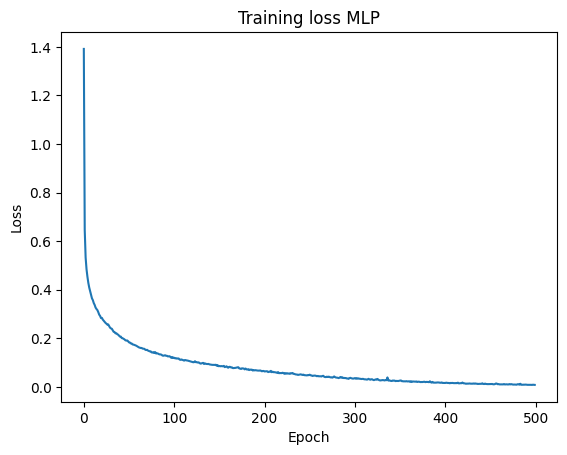

In [11]:
Zs_test, As_test = linear_forward(X_test_encoded, W_clf, B_clf, act_clf, act_f_clf)
L = len(W_clf)
pred = np.argmax(As_test[L], axis=1)

y_test_subset = y_test[:len(pred)]
accuracy = np.mean(pred == y_test_subset)
print(f"Accuracy : {accuracy * 100:.2f}%")

n_classes = 10
recall_par_classe    = np.zeros(n_classes)
precision_par_classe = np.zeros(n_classes)
f1_par_classe        = np.zeros(n_classes)

for c in range(n_classes):
    TP = np.sum((pred == c) & (y_test_subset == c))
    FP = np.sum((pred == c) & (y_test_subset != c))
    FN = np.sum((pred != c) & (y_test_subset == c))
    precision_par_classe[c] = TP / (TP + FP) if (TP + FP) > 0 else 0
    recall_par_classe[c]    = TP / (TP + FN) if (TP + FN) > 0 else 0
    f1_par_classe[c]        = (2 * precision_par_classe[c] * recall_par_classe[c] /
                               (precision_par_classe[c] + recall_par_classe[c])
                               if (precision_par_classe[c] + recall_par_classe[c]) > 0 else 0)

print(f"\n{'Classe':<10} {'Precision':>10} {'Recall':>10} {'F1':>10}")
print("-" * 42)
for c in range(n_classes):
    print(f"{c:<10} {precision_par_classe[c]:>10.3f} {recall_par_classe[c]:>10.3f} {f1_par_classe[c]:>10.3f}")
print("-" * 42)
print(f"{'Moyenne':<10} {np.mean(precision_par_classe):>10.3f} {np.mean(recall_par_classe):>10.3f} {np.mean(f1_par_classe):>10.3f}")

plt.plot(cout_clf)
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("Training loss MLP")
plt.show()

## Import des données du projet

In [22]:
images_train  = np.load(r"D:\INSA\3-A BS\UE7- Image_ML\ML\images_train.npy")
images_test   = np.load(r"D:\INSA\3-A BS\UE7- Image_ML\ML\images_test.npy")
labels_train  = np.load(r"D:\INSA\3-A BS\UE7- Image_ML\ML\labels_train.npy")
labels_test   = np.load(r"D:\INSA\3-A BS\UE7- Image_ML\ML\labels_test.npy")

print("images_train shape:", images_train.shape)
print("images_test shape: ", images_test.shape)
print("labels_train shape:", labels_train.shape)
print("labels_test shape: ", labels_test.shape)

# conversion directe string → int
classes = sorted(np.unique(labels_train))  # ['classe_A', 'classe_B', 'classe_C']
label_to_int = {label: i for i, label in enumerate(classes)}

labels_train_int = np.array([label_to_int[l] for l in labels_train])
labels_test_int  = np.array([label_to_int[l] for l in labels_test])

print(label_to_int)          # pour savoir quel int correspond à quel label
print(labels_train_int[:5])  # vérification

# 129*65 = 8385 pixels
N_train = images_train.shape[0]
N_test  = images_test.shape[0]
nb_pixels  = images_train.shape[1] * images_train.shape[2]  # H * W automatique
n_classes  = len(np.unique(labels_train))                   # nombre de classes automatique
img_shape  = images_train.shape[1:]
D=img_shape[1]
E=img_shape[0]

print(f"Nb pixels par image : {nb_pixels}")
print(f"Nb classes : {n_classes}")

X_train = (images_train.reshape(N_train, nb_pixels) / np.float32(255.0))
X_test  = (images_test.reshape(N_test,   nb_pixels) / np.float32(255.0))

# 3 classes
Y_train = tf.keras.utils.to_categorical(labels_train_int, n_classes).astype(np.float32)
Y_test  = tf.keras.utils.to_categorical(labels_test_int,  n_classes).astype(np.float32)

print(X_train.shape)  # (N_train, 8385)
print(Y_train.shape)  # (N_train, 3)

images_train shape: (120, 129, 65)
images_test shape:  (30, 129, 65)
labels_train shape: (120,)
labels_test shape:  (30,)
{np.str_('Cat'): 0, np.str_('Chicken'): 1, np.str_('Sheep'): 2}
[1 2 1 0 0]
129
Nb pixels par image : 8385
Nb classes : 3
(120, 8385)
(120, 3)


## Entrainement de l'auto-encodeur

Epoch 0/1500 — Loss: 0.2478
Epoch 5/1500 — Loss: 0.2478
Epoch 10/1500 — Loss: 0.2478
Epoch 15/1500 — Loss: 0.2478
Epoch 20/1500 — Loss: 0.2478
Epoch 25/1500 — Loss: 0.2478
Epoch 30/1500 — Loss: 0.2478
Epoch 35/1500 — Loss: 0.2478
Epoch 40/1500 — Loss: 0.2478
Epoch 45/1500 — Loss: 0.2478
Epoch 50/1500 — Loss: 0.2478
Epoch 55/1500 — Loss: 0.2478
Epoch 60/1500 — Loss: 0.2478
Epoch 65/1500 — Loss: 0.2478
Epoch 70/1500 — Loss: 0.2478
Epoch 75/1500 — Loss: 0.2477
Epoch 80/1500 — Loss: 0.2477
Epoch 85/1500 — Loss: 0.2477
Epoch 90/1500 — Loss: 0.2477
Epoch 95/1500 — Loss: 0.2477
Epoch 100/1500 — Loss: 0.2477
Epoch 105/1500 — Loss: 0.2477
Epoch 110/1500 — Loss: 0.2477
Epoch 115/1500 — Loss: 0.2477
Epoch 120/1500 — Loss: 0.2477
Epoch 125/1500 — Loss: 0.2477
Epoch 130/1500 — Loss: 0.2477
Epoch 135/1500 — Loss: 0.2477
Epoch 140/1500 — Loss: 0.2477
Epoch 145/1500 — Loss: 0.2477
Epoch 150/1500 — Loss: 0.2477
Epoch 155/1500 — Loss: 0.2477
Epoch 160/1500 — Loss: 0.2477
Epoch 165/1500 — Loss: 0.2477
Ep

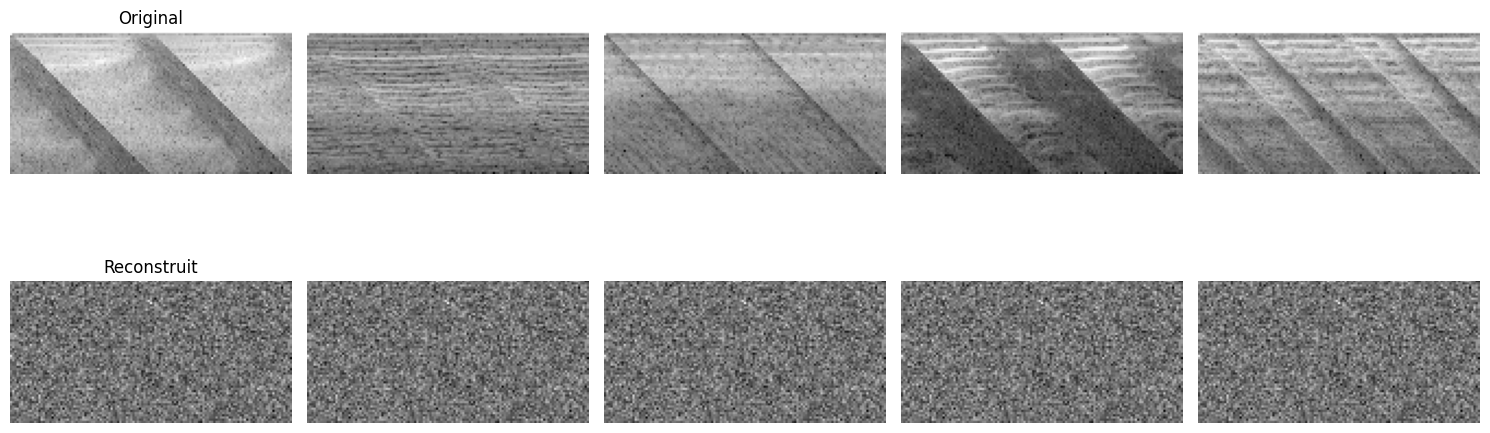

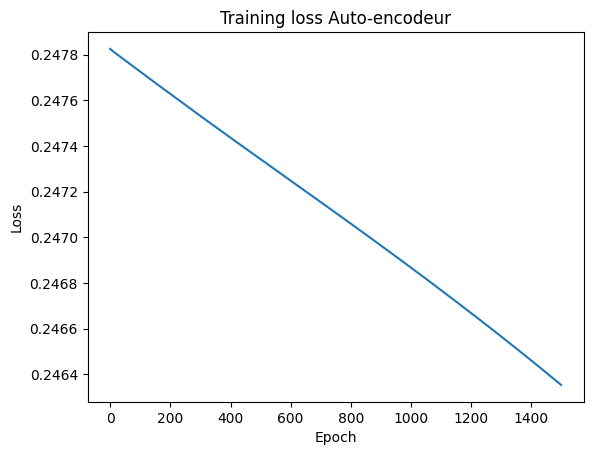

In [21]:
# 8385 → goulot 64
W_ae, B_ae = init_params(
    layer_sizes=[8385, 512, 64, 512, 8385],  # ← adapté à 8385 pixels
    init_type="he",
    seed=42
)

act_ae   = Relu
act_f_ae = sigmoid

W_ae, B_ae, cout_ae = Mini_Batch(
    X=X_train,
    Y=X_train,
    nb_epoch=1500,
    Lr=0.05,
    W=W_ae,
    B=B_ae,
    Nom_tech_Loss=MSE_reconstruction,
    Nom_tech_activation=act_ae,
    act_finale=act_f_ae,
    batch_size=128,
    clip=5.0
)
vue_reconstruite(X_test, W_ae, B_ae, act=act_ae, act_finale=act_f_ae, D=D, E=E, n=5)
plt.plot(cout_ae)
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("Training loss Auto-encodeur")
plt.show()

## Entrainement du MLP

In [ ]:
X_train_encoded = encode(X_train, W_ae, B_ae, act_ae)  # (N_train, 64)
X_test_encoded  = encode(X_test,  W_ae, B_ae, act_ae)  # (N_test, 64)

print("X_train_encoded shape:", X_train_encoded.shape)
print("X_test_encoded shape: ", X_test_encoded.shape)

W_clf, B_clf = init_params(
    layer_sizes=[64, 128, 64, 3],  # ← entrée 64, sortie 3 classes
    init_type="he",
    seed=42
)

act_clf   = Relu
act_f_clf = softmax

W_clf, B_clf, cout_clf = Mini_Batch(
    X=X_train_encoded,
    Y=Y_train,
    nb_epoch=200,
    Lr=0.01,
    W=W_clf,
    B=B_clf,
    Nom_tech_Loss=cross_entropy,
    Nom_tech_activation=act_clf,
    act_finale=act_f_clf,
    batch_size=64,
    clip=None
)

## Test Auto-encodeur+ MLP

In [ ]:
Zs_test, As_test = linear_forward(X_test_encoded, W_clf, B_clf, act_clf, act_f_clf)
L = len(W_clf)
pred = np.argmax(As_test[L], axis=1)

y_test_subset = labels_test[:len(pred)]
accuracy = np.mean(pred == y_test_subset)
print(f"Accuracy : {accuracy * 100:.2f}%")

n_classes = 3
recall_par_classe    = np.zeros(n_classes)
precision_par_classe = np.zeros(n_classes)
f1_par_classe        = np.zeros(n_classes)

for c in range(n_classes):
    TP = np.sum((pred == c) & (y_test_subset == c))
    FP = np.sum((pred == c) & (y_test_subset != c))
    FN = np.sum((pred != c) & (y_test_subset == c))
    precision_par_classe[c] = TP / (TP + FP) if (TP + FP) > 0 else 0
    recall_par_classe[c]    = TP / (TP + FN) if (TP + FN) > 0 else 0
    f1_par_classe[c]        = (2 * precision_par_classe[c] * recall_par_classe[c] /
                               (precision_par_classe[c] + recall_par_classe[c])
                               if (precision_par_classe[c] + recall_par_classe[c]) > 0 else 0)

print(f"\n{'Classe':<10} {'Precision':>10} {'Recall':>10} {'F1':>10}")
print("-" * 42)
for c in range(n_classes):
    print(f"{c:<10} {precision_par_classe[c]:>10.3f} {recall_par_classe[c]:>10.3f} {f1_par_classe[c]:>10.3f}")
print("-" * 42)
print(f"{'Moyenne':<10} {np.mean(precision_par_classe):>10.3f} {np.mean(recall_par_classe):>10.3f} {np.mean(f1_par_classe):>10.3f}")

plt.plot(cout_clf)
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("Training loss MLP")
plt.show()